<a href="https://colab.research.google.com/github/Existanze54/sirius-machine-learning-2026/blob/main/Homeworks/HW4_DimRed_Clust.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Домашка 4. Снижение размерности и кластеризация

### imports

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD

from sklearn.preprocessing import Normalizer
from sklearn.model_selection import train_test_split

from sklearn.pipeline import Pipeline
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score

## Задача 1. Цветочек

In [ ]:
%%bash
FILEID=1_2EL7UkAYqslVOZDle5I4Iuw24NnItWo
wget -q --no-check-certificate "https://docs.google.com/uc?export=download&id=$FILEID" -O flower.png

Имеется цветное изображение цветка с разрешением `640x427` пикселей с названием `flower.png`. Загрузим это изображение в переменную `img` в виде трехмерного массива чисел.

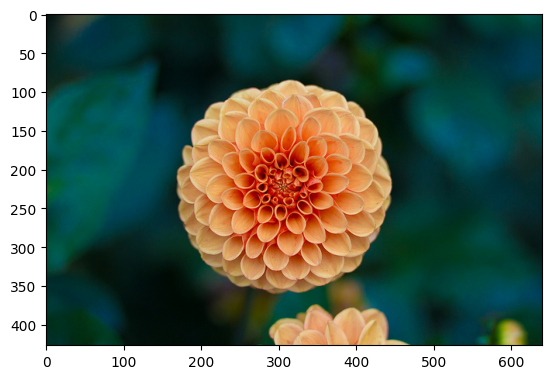

In [ ]:
img = plt.imread("flower.png")[:, :, :3]
_ = plt.imshow(img)

Каждый пиксель в цветовом пространстве RGB описывается тремя числами $(r, g, b)$ — интенсивностями красного, зеленого и синего каналов. Эти три значения и служат признаками пикселя.

Преобразуем изображение в массив формы $(273\,280, 3)$. Каждая строка соответствует одному из $640 \times 427$ пикселей и содержит интенсивности трех цветовых каналов RGB.

Разобьем пиксели на четыре кластера методом k-средних. Из атрибута `cluster_centers_` обученной модели получим RGB-координаты центроидов и покажем соответствующие цвета в виде палитры.

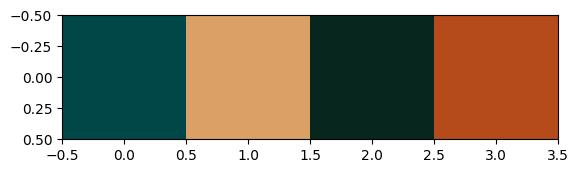

In [ ]:
X = img.reshape(-1, 3)
kmeans = KMeans(n_clusters=4, random_state=42).fit(X)
centroids = kmeans.cluster_centers_
_ = plt.imshow([centroids])

Заменим RGB-значения каждого пикселя в матрице `X` на RGB-значения центроида его кластера. Полученную матрицу назовем `qX`. Визуализируем результат.

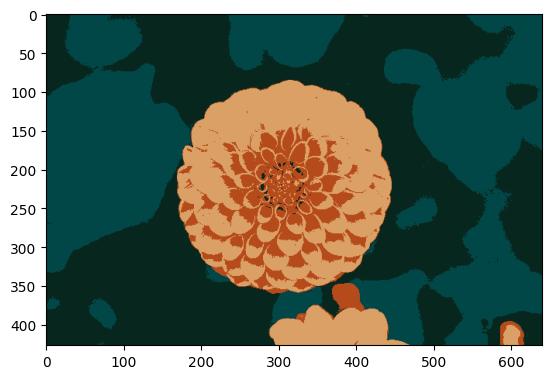

In [ ]:
qX = centroids[kmeans.labels_]
_= plt.imshow(qX.reshape(img.shape))

Выполните кластеризацию пикселей с помощью `KMeans` для каждого $k$ от 2 до 25 включительно. Рассчитайте **индекс Дэвиса–Булдина** для каждого $k$, постройте график зависимости индекса от числа кластеров и выберите $k$ методом локтя.

Для выбранного $k$ замените цвет каждого пикселя цветом центроида его кластера. Покажите исходное и квантованное изображения рядом для сравнения.

In [ ]:
# your code here

## Задача 2. Кластеризация молекул

### Подготовка данных

Загрузим датасет [ESOL](https://www.kaggle.com/c/drug-solubility-challenge/data), с которым мы уже работали.

In [ ]:
! wget -q https://raw.githubusercontent.com/deepchem/deepchem/master/datasets/delaney-processed.csv

In [ ]:
df = pd.read_csv('delaney-processed.csv')
smis = df['smiles']

Чаще всего в датасетах органические молекулы представлены как [SMILES](https://en.wikipedia.org/wiki/Simplified_Molecular_Input_Line_Entry_System) — это простой и (почти) универсальный способ представления молекулярного графа в виде строки. Мы будем конвертировать их в молекулярные фингрепринты — это такое векторное представление молекулы, которое содержит `1` при наличии какого-то подграфа и `0` при его отсутствии.  
<img src="https://www.mdpi.com/pharmaceuticals/pharmaceuticals-16-01259/article_deploy/html/images/pharmaceuticals-16-01259-g005.png" width='750'>

Для этого мы используем библиотеку `datamol`, которая является современной более дружелюбной оберткой над `rdkit`.

In [ ]:
! pip -q install datamol

In [ ]:
import datamol as dm

X = np.array([dm.to_fp(smi, fp_type='ecfp') for smi in smis])
X

Фингерпринты очень разреженные (это значит, что большинство значений равны нулю). На таких данных лучше работает не обычный `PCA`, а его вариация `TruncatedSVD`. Фингерпринты перед ним можно не нормализовать, а вот после лучше это сделать для облегчения кластеризации. Обращаю ванимание, что нормализуем мы не по столбцам, как обычно, а по строкам.

In [ ]:
pipe = Pipeline([
    ('red', TruncatedSVD(n_components=64,
                         random_state=0)),
    ('norm', Normalizer()),
    ('clust', KMeans(max_iter=1000,
                     random_state=0)),
])

### Подбор числа кластеров

Подберите число кластеров в диапазоне $[3, 49]$, оценив коэффициент силуэта (`silhouette_score`) по исходным фингерпринтам с мерой Жаккара (`metric='jaccard'`) на валидационной выборке.

In [ ]:
# your code here

### Визуализация

In [ ]:
from umap.umap_ import UMAP

Переобучите `pipe` с лучшим числом кластеров на полном датасете. С помощью `UMAP` снизьте фингерпринты до двух измерений (на полном датасете). Используйте `metric='jaccard'` и остальные параметры по умолчанию. Изобразите результат на диаграмме рассеяния, отметив различные кластера цветом.

In [ ]:
# your code here

С помощью "ящика с усами" (`plt.boxplot`/`sns.boxplot`) визуализируйте распределение измеренной растворимости (`'measured log solubility in mols per litre'`) в зависимости от кластера.

In [ ]:
# your code here

In [ ]:
# @title Небольшая функция для рисования молекул
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem.Draw import IPythonConsole
from rdkit.Chem import rdDepictor
IPythonConsole.drawOptions.minFontSize = 8
IPythonConsole.drawOptions.bondLineWidth = 1.5
IPythonConsole.ipython_useSVG = True
rdDepictor.SetPreferCoordGen(True)

def plot_mol_from_smiles(smi):
    mol = Chem.MolFromSmiles(smi)
    display(Draw.MolToImage(mol))

Используя функцию `plot_mol_from_smiles`, изобразите несколько молекул из нескольких кластеров с самой низкой средней растворимостью.

In [ ]:
# your code here